# Import Library

In [1]:
import numpy as np
from numpy import where
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from collections import Counter
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from imblearn.over_sampling import RandomOverSampler, SMOTE, BorderlineSMOTE, SVMSMOTE, ADASYN
from imblearn.under_sampling import RandomUnderSampler, NearMiss, TomekLinks
from sklearn.neural_network import MLPClassifier
from imblearn.pipeline import Pipeline
from sklearn import clone
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score


Matplotlib is building the font cache; this may take a moment.


In [2]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_validate
from sklearn.neural_network import MLPClassifier
warnings.filterwarnings('ignore', category=ConvergenceWarning)  # MLP default max_iter=200 sering belum konvergen; dibahas di 5d

# Soal

> **Catatan penggunaan AI:** notebook ini dikerjakan dengan bantuan AI assistant (Claude). Seluruh sel sudah dijalankan; angka pada jawaban diambil dari hasil eksekusi, dan deskripsi grafik dicocokkan dengan scatter plot masing-masing.

### **Ketentuan:**

1. Dokumen template lab dengan format .ipynb dan dataset (jika dibutuhkan) telah disediakan.
2. Jalankan kode pada dokumen .ipynb dan perhatikan dengan saksama apa yang potongan kode tersebut lakukan beserta dengan keluarannya. Jawablah **pertanyaan** yang disisipkan pada potongan program yang diberikan.
3. Dokumen Jupyter Notebook yang telah dilengkapi dengan jawaban dikumpulkan dalam sebuah repositori Git (misalnya, di GitHub atau GitLab) dan kirimkan tautannya kepada kami.
4. Sebelum di kumpulkan, kode **WAJIB** dijalankan.

## Deskripsi Dataset

Dataset yang akan dipakai pada soal ini adalah dataset [Bank Customer Churn](https://www.kaggle.com/datasets/radheshyamkollipara/bank-customer-churn) dengan sedikit modifikasi. Silahkan klik link tersebut untuk mengetahui penjelasan fitur-fiturnya.

Target variable pada dataset ini adalah `Exited`. Jumlah customer yang tidak meninggalkan bank (`Exited=0`) adalah 7962, sedangkan jumlah customer yang meninggalkan bank (`Exited=1`) adalah 159. Ini membuat dataset menjadi imbalance dan anda akan menangani kasus imbalance data tersebut.

In [3]:
df=pd.read_csv('Customer-Churn-Records-v2.csv')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8121 entries, 0 to 8120
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   CreditScore         8121 non-null   int64  
 1   Geography           8121 non-null   str    
 2   Gender              8121 non-null   str    
 3   Age                 8121 non-null   int64  
 4   Tenure              8121 non-null   int64  
 5   Balance             8121 non-null   float64
 6   NumOfProducts       8121 non-null   int64  
 7   HasCrCard           8121 non-null   int64  
 8   IsActiveMember      8121 non-null   int64  
 9   EstimatedSalary     8121 non-null   float64
 10  Exited              8121 non-null   int64  
 11  Complain            8121 non-null   int64  
 12  Satisfaction Score  8121 non-null   int64  
 13  Card Type           8121 non-null   str    
 14  Point Earned        8121 non-null   int64  
dtypes: float64(2), int64(10), str(3)
memory usage: 951.8 KB


In [5]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,757,Germany,Female,34,9,101861.36,2,0,0,187011.96,0,0,5,PLATINUM,903
1,644,France,Male,33,8,0.00,2,1,1,155294.17,0,0,5,SILVER,813
2,655,Spain,Female,56,5,0.00,2,1,1,41782.70,0,0,2,PLATINUM,979
3,710,Spain,Female,36,8,0.00,2,0,0,83206.19,0,0,3,SILVER,636
4,684,Spain,Female,31,8,0.00,2,1,0,188637.05,0,0,4,SILVER,515


In [6]:
df['Exited'].value_counts()

Exited
0    7962
1     159
Name: count, dtype: int64

## 1. Imbalanced dataset

a) Buatlah sebuah dataset baru yang terdiri dari kolom `EstimatedSalary` dan kolom `Balance` sebagai fitur-fiturnya (X), dan kolom `Exited` sebagai target (y).

In [7]:
X = df[['EstimatedSalary', 'Balance']].values
y = df['Exited'].values
print(X.shape, y.shape)

(8121, 2) (8121,)


b) Hitung jumlah masing-masing target (Hint: Counter).

In [8]:
print(Counter(y))

Counter({np.int64(0): 7962, np.int64(1): 159})


c) Visualisasikan dataset pada soal (1a) dengan scatter plot. Berikan warna yang berbeda untuk setiap kelasnya

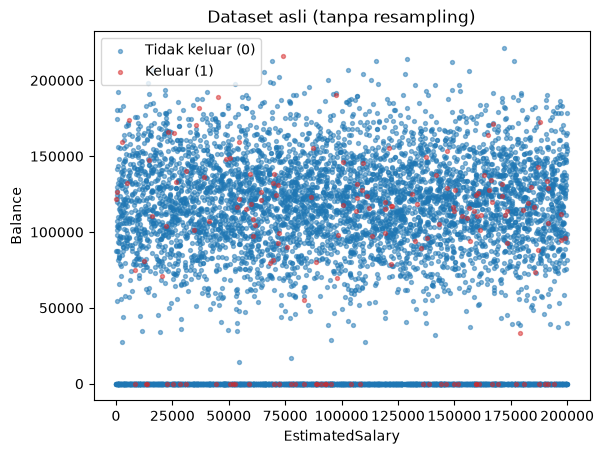

In [9]:
def plot_dataset(X, y, title):
    for label, name, color in [(0, 'Tidak keluar (0)', 'tab:blue'), (1, 'Keluar (1)', 'tab:red')]:
        plt.scatter(X[y == label, 0], X[y == label, 1], s=8, alpha=0.5, c=color, label=name)
    plt.xlabel('EstimatedSalary'); plt.ylabel('Balance'); plt.title(title); plt.legend(); plt.show()

plot_dataset(X, y, 'Dataset asli (tanpa resampling)')

d) Lengkapilah fungsi di bawah ini untuk melakukan oversampling pada setiap fold ketika melakukan cross validation pada suatu model menggunakan StratifiedKFold dengan k=5, shuffle=True, dan random_state=42. Tampilkan juga rata-rata skor accuracy, f1 macro, precision macro, dan recall macro.

Jalankan fungsi tersebut dengan menggunakan:
- DecisionTreeClassifier, dengan random_state=42
- Teknik oversampling RandomOversampler, dengan random_state=42
- X dan y yang didefinisikan pada soal (1a)

*(Pastikan validation test dataset tidak terganggu oleh penambahan data - data sintetis.)*

In [10]:
def train_and_evaluate_with_oversampling(model, X, y, resample_method):
    # StratifiedKFold biasa, 5 fold
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

    # List skor tiap fold
    accuracies, f1_scores, precisions, recalls = [], [], [], []

    for fold, (train_index, test_index) in enumerate(skf.split(X, y), 1):
        X_train = X[train_index]
        y_train = y[train_index]
        X_test = X[test_index]
        y_test = y[test_index]

        # Resampling HANYA pada data latih; data validasi dibiarkan asli
        X_train_sampled, y_train_sampled = resample_method.fit_resample(X_train, y_train)

        model_clone = clone(model)  # model baru di setiap fold
        model_clone.fit(X_train_sampled, y_train_sampled)
        y_pred = model_clone.predict(X_test)

        accuracies.append(accuracy_score(y_test, y_pred))
        f1_scores.append(f1_score(y_test, y_pred, average="macro"))
        precisions.append(precision_score(y_test, y_pred, average="macro"))
        recalls.append(recall_score(y_test, y_pred, average="macro"))

    print("Mean scores across all folds:")
    print(f'Mean Accuracy: {np.mean(accuracies)}')
    print(f'Mean F1-score (macro): {np.mean(f1_scores)}')
    print(f'Mean Precision (macro): {np.mean(precisions)}')
    print(f'Mean Recall (macro): {np.mean(recalls)}')
    # return ditambahkan supaya skor bisa dibandingkan di soal berikutnya
    return {'accuracy': np.mean(accuracies), 'f1_macro': np.mean(f1_scores),
            'precision_macro': np.mean(precisions), 'recall_macro': np.mean(recalls)}

In [11]:
res_1d = train_and_evaluate_with_oversampling(
    DecisionTreeClassifier(random_state=42), X, y, RandomOverSampler(random_state=42))

Mean scores across all folds:
Mean Accuracy: 0.9635509662751043
Mean F1-score (macro): 0.4976120916265085
Mean Precision (macro): 0.497570140331623
Mean Recall (macro): 0.49772234982701613


e) Jalankan kode di bawah ini. Apakah terdapat perbedaan skor dengan yang ada pada soal (1d)? Jika berbeda, mengapa hal tersebut bisa terjadi, dan approach manakah yang lebih tepat untuk dilakukan (approach (1d) atau (1e))?

In [12]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_oversampled, y_oversampled = RandomOverSampler(random_state=42).fit_resample(X, y)

scoring = ['accuracy','f1_macro', 'precision_macro', 'recall_macro']
for i in range(len(scoring)):
  score = cross_val_score(DecisionTreeClassifier(random_state=42), X_oversampled, y_oversampled, scoring=scoring[i], cv=cv, n_jobs=-1)
  print(f"{scoring[i]} score: {np.mean(score)}")

accuracy score: 0.9889476030071865
f1_macro score: 0.9889460502661436
precision_macro score: 0.9891971322065523


recall_macro score: 0.9889470500651404


**Jawaban:** Ya, berbeda jauh.

| | accuracy | F1 macro | precision macro | recall macro |
|---|---|---|---|---|
| (1d) oversampling di dalam tiap fold | 0,9636 | **0,4976** | 0,4976 | 0,4977 |
| (1e) oversampling sebelum CV | 0,9889 | **0,9889** | 0,9892 | 0,9889 |

**Mengapa:** di (1e) `RandomOverSampler` dijalankan pada *seluruh* dataset sebelum CV. Ia menggandakan 159 sampel minoritas menjadi 7.962 salinan, sehingga salinan yang identik jatuh ke data latih **dan** data validasi (*data leakage*). `DecisionTreeClassifier` tanpa batas kedalaman menghafal titik-titik itu, lalu "menebak benar" pada salinannya di validasi. Skor 0,989 itu palsu.

**Approach yang tepat: (1d).** Resampling hanya boleh dilakukan pada data latih tiap fold, sedangkan data validasi harus tetap berdistribusi asli (±2% minoritas), karena itulah kondisi saat model dipakai di dunia nyata. Hasil jujurnya F1 macro ≈ 0,50, setara tebakan acak. Ini bisa dipahami: dua fitur yang dipakai (`EstimatedSalary`, `Balance`) hampir tidak berkorelasi dengan `Exited` (korelasi 0,016 dan 0,036), jadi memang hampir tidak ada sinyal yang bisa dipelajari.

Referensi: scikit-learn, *Common pitfalls and recommended practices* (bagian *Data leakage*), https://scikit-learn.org/stable/common_pitfalls.html; Santos, M. S. et al. (2018). *Cross-validation for imbalanced datasets: avoiding overoptimistic and overfitting approaches*. IEEE Computational Intelligence Magazine, 13(4), 59–76.

f) Mengapa StratifiedKFold umumnya lebih sering digunakan dalam kasus Imbalanced dataset dibandingkan KFold biasa? Jelaskan serta berikan sumber referensi anda.

**Jawaban:** `StratifiedKFold` menjaga agar proporsi kelas di setiap fold sama dengan proporsi di seluruh dataset. `KFold` biasa membagi secara acak tanpa melihat label.

Pada data ini minoritas hanya 159 dari 8.121 (±2%). Dengan `KFold` acak, jumlah minoritas per fold bisa sangat bervariasi, bahkan bisa nyaris nol di satu fold. Akibatnya metrik kelas minoritas (precision, recall, F1) menjadi tidak stabil atau tidak terdefinisi, dan estimasi performa punya varians tinggi. Dengan stratifikasi, tiap fold berisi ±32 sampel minoritas (159 / 5), sehingga setiap fold sama-sama bisa menguji kemampuan model mengenali kelas minoritas dan estimasinya lebih stabil. Kohavi (1995) menemukan stratifikasi menurunkan bias dan varians estimasi akurasi dibanding CV biasa.

Referensi: Kohavi, R. (1995). *A study of cross-validation and bootstrap for accuracy estimation and model selection*. IJCAI-95, 1137–1143; scikit-learn User Guide, *Cross-validation: evaluating estimator performance* (bagian *Cross-validation iterators with stratification based on class labels*), https://scikit-learn.org/stable/modules/cross_validation.html.

## 2. Oversampling

a) Terapkan metode oversampling yang paling sesuai menurut anda dan bisa diterapkan dengan dataset soal (1a). Visualisasikan scatter plot hasil resampling datasetnya

SMOTE: Counter({np.int64(0): 7962, np.int64(1): 7962})


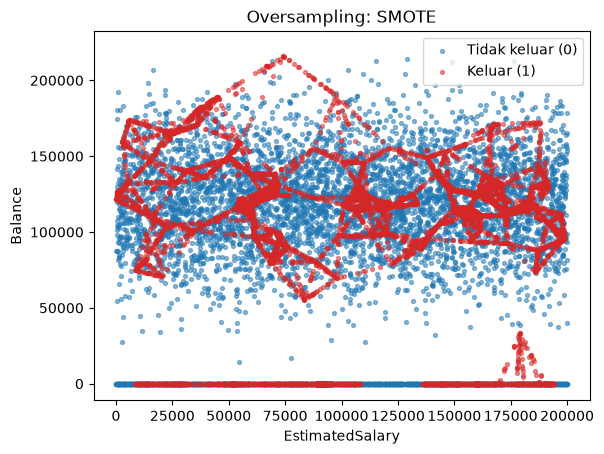

In [13]:
X_smote, y_smote = SMOTE(random_state=42).fit_resample(X, y)
print('SMOTE:', Counter(y_smote))
plot_dataset(X_smote, y_smote, 'Oversampling: SMOTE')

b) Terapkan metode oversampling yang lain yang berbeda dengan metode pada soal (2a). Visualisasikan scatter plot hasil resampling datasetnya

ADASYN: Counter({np.int64(1): 7999, np.int64(0): 7962})


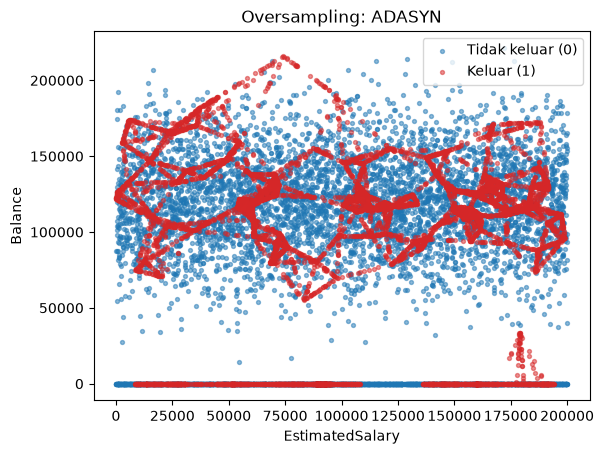

In [14]:
X_adasyn, y_adasyn = ADASYN(random_state=42).fit_resample(X, y)
print('ADASYN:', Counter(y_adasyn))
plot_dataset(X_adasyn, y_adasyn, 'Oversampling: ADASYN')

c) Adakah perbedaan yang Anda temukan dari pengamatan terhadap data hasil kedua metode oversampling yang Anda pilih? Jika ada, jelaskan mengapa perbedaan tersebut bisa terjadi! Sertakan sumber referensi anda

**Jawaban:** Jumlah hasilnya sedikit berbeda: SMOTE menghasilkan tepat 7.962 : 7.962, sedangkan ADASYN 7.999 (minoritas) : 7.962 (mayoritas). ADASYN tidak persis seimbang karena jumlah titik baru ditentukan per sampel lewat pembobotan, lalu dibulatkan.

Secara visual, kedua scatter plot **hampir sama**. Pada keduanya:
- Titik sintetis (merah) membentuk **garis-garis lurus**. Ini karena SMOTE dan ADASYN membuat titik baru di sepanjang garis antara satu sampel minoritas dan salah satu tetangga minoritas terdekatnya. Minoritas hanya 159 titik yang tersebar jarang, sehingga tetangganya sering jauh dan garisnya panjang, memotong daerah yang dipenuhi mayoritas.
- Di pita `Balance = 0`, titik merah memenuhi hampir seluruh rentang gaji, kecuali celah sekitar gaji 110–135 ribu.
- Muncul "tonjolan" merah di sekitar gaji ±180 ribu dengan saldo 0–35 ribu, hasil interpolasi antara satu nasabah keluar bersaldo ±33 ribu dan nasabah keluar di pita saldo 0. Di data asli daerah ini kosong.

Perbedaannya hanya pada kepadatan beberapa segmen garis. Ini sesuai cara kerja ADASYN: sampel minoritas yang tetangganya lebih banyak mayoritas mendapat lebih banyak titik sintetis. Pada data ini minoritas bercampur penuh dengan mayoritas: 148 dari 159 sampel minoritas (93%) seluruh 5 tetangga terdekatnya adalah mayoritas, dan 11 sisanya 4 dari 5. Bobotnya jadi hampir seragam, sehingga ADASYN berperilaku hampir sama dengan SMOTE.

Referensi: Chawla, N. V. et al. (2002). *SMOTE: Synthetic Minority Over-sampling Technique*. JAIR, 16, 321–357; He, H., Bai, Y., Garcia, E. A., & Li, S. (2008). *ADASYN: Adaptive synthetic sampling approach for imbalanced learning*. IEEE IJCNN, 1322–1328; dokumentasi imbalanced-learn, *Over-sampling*, https://imbalanced-learn.org/stable/over_sampling.html.

d) Lakukan cross validation menggunakan StratifiedKFold dengan k=5 pada 2 buah model Decision Tree yang berbeda dengan ketentuan berikut:
- Model pertama menggunakan metode oversampling yang dipakai pada (2a)
- Model kedua menggunakan metode oversampling yang dipakai pada (2b)
- Metrik utama yang digunakan adalah f1 macro.
- Oversampling dilakukan pada setiap fold cross validation

Petunjuk: Anda bisa menggunakan cara 1d untuk menjawab soal ini.

*(Pastikan validation test dataset tidak terganggu oleh penambahan data - data sintetis.)*

In [15]:
print('== SMOTE =='); r_smote = train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, SMOTE(random_state=42))
print('== ADASYN =='); r_adasyn = train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, ADASYN(random_state=42))
pd.DataFrame({'SMOTE': r_smote, 'ADASYN': r_adasyn}).T

== SMOTE ==


Mean scores across all folds:
Mean Accuracy: 0.7194924592648732
Mean F1-score (macro): 0.4388088244142233
Mean Precision (macro): 0.5020141611930754
Mean Recall (macro): 0.5208467622369588
== ADASYN ==


Mean scores across all folds:
Mean Accuracy: 0.7093953012504738
Mean F1-score (macro): 0.43051239013675147
Mean Precision (macro): 0.4982945106339294
Mean Recall (macro): 0.4818125190605844


,accuracy,f1_macro,precision_macro,recall_macro
SMOTE,0.719492,0.438809,0.502014,0.520847
ADASYN,0.709395,0.430512,0.498295,0.481813


e) Metode manakah yang memberikan skor F1 makro tertinggi? Jelaskan mengapa hal tersebut bisa terjadi.

**Jawaban:** **SMOTE** (F1 macro 0,4388) sedikit lebih tinggi daripada **ADASYN** (0,4305), tetapi selisihnya hanya ±0,008, jadi praktis setara dan tidak bisa disimpulkan signifikan dengan hanya 159 sampel minoritas.

Kemungkinan penyebab selisih kecil itu: ADASYN menaruh lebih banyak titik sintetis tepat di area yang bercampur dengan mayoritas, jadi pohon keputusan mempelajari batas yang lebih berisik. Perhatikan juga bahwa keduanya (0,43–0,44) bahkan lebih rendah daripada `RandomOverSampler` di soal 1d (0,4976). Titik sintetis mengisi daerah di tengah awan mayoritas dengan label minoritas, sehingga pohon sering memprediksi "keluar" untuk nasabah yang sebenarnya bertahan (akurasi turun ke ±0,72). Penyebab dasarnya tetap sama: kedua fitur tidak membawa informasi tentang `Exited`, jadi teknik oversampling apa pun tidak bisa menciptakan sinyal yang tidak ada.

## 3. Undersampling

a) Terapkan metode undersampling yang paling sesuai menurut anda dan bisa diterapkan dengan dataset soal (1a). Visualisasikan scatter plot hasil resampling datasetnya

RandomUnderSampler: Counter({np.int64(0): 159, np.int64(1): 159})


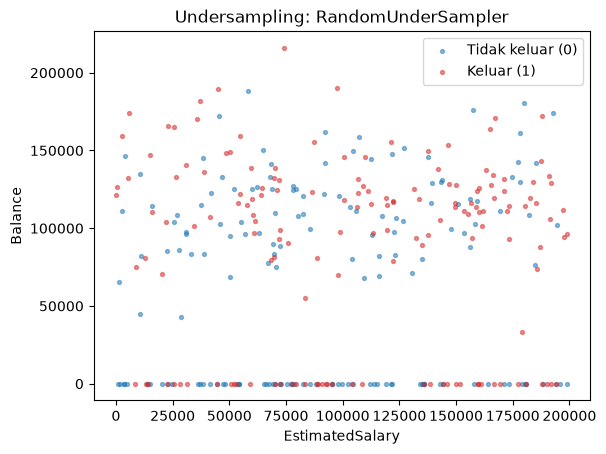

In [16]:
X_rus, y_rus = RandomUnderSampler(random_state=42).fit_resample(X, y)
print('RandomUnderSampler:', Counter(y_rus))
plot_dataset(X_rus, y_rus, 'Undersampling: RandomUnderSampler')

b) Terapkan metode undersampling lain yang berbeda dengan metode pada soal (3a). Visualisasikan scatter plot hasil resampling datasetnya

NearMiss-1:

 Counter({np.int64(0): 159, np.int64(1): 159})


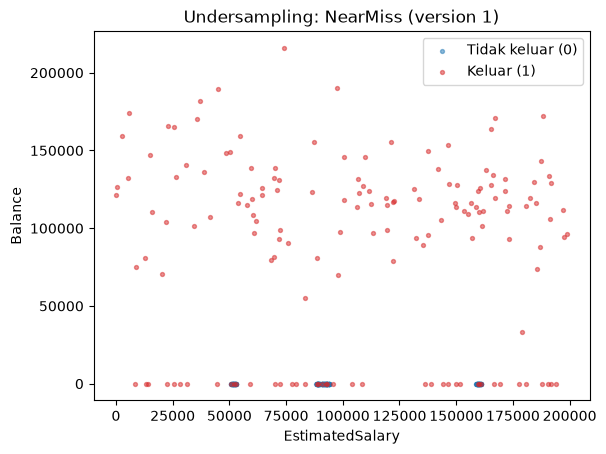

In [17]:
X_nm, y_nm = NearMiss(version=1).fit_resample(X, y)
print('NearMiss-1:', Counter(y_nm))
plot_dataset(X_nm, y_nm, 'Undersampling: NearMiss (version 1)')

c) Berdasarkan visualisasi scatter plot kedua dataset hasil resampling pada soal (3a) dan (3b) yang Anda pilih, apa perbedaan yang terlihat? Jelaskan juga mengapa perbedaan tersebut bisa terjadi! Jangan lupa sertakan sumber referensi anda

**Jawaban:** Keduanya menyisakan 159 sampel mayoritas (159 : 159), tetapi letak mayoritas yang tersisa sangat berbeda:

- **RandomUnderSampler:** 159 titik biru tersebar di seluruh plot, baik di pita `Balance = 0` maupun di awan saldo 50–200 ribu. Bentuk sebaran aslinya terjaga: 40% mayoritas yang tersisa bersaldo 0, hampir sama dengan data asli (39%), hanya jauh lebih jarang.
- **NearMiss-1:** **seluruh** 159 titik biru berada di pita `Balance = 0`, menumpuk di beberapa kelompok sempit (sekitar gaji 50 ribu, 80–90 ribu, dan 150–160 ribu) dan tertutup titik merah. Di daerah saldo di atas 0 tidak ada mayoritas yang tersisa sama sekali.

Mengapa: RandomUnderSampler memilih secara acak tanpa melihat jarak. NearMiss-1 menyimpan sampel mayoritas yang rata-rata jaraknya ke 3 minoritas terdekat paling kecil. Di pita saldo 0, banyak nasabah keluar dan bertahan yang saldonya sama persis (0), sehingga jarak di antara mereka hanya ditentukan selisih gaji dan menjadi sangat kecil. Titik mayoritas di sanalah yang selalu terpilih. Akibatnya data hasil NearMiss tidak lagi mewakili distribusi asli, karena seluruh daerah saldo di atas 0 hanya berisi minoritas.

Referensi: Zhang, J. & Mani, I. (2003). *kNN approach to unbalanced data distributions: a case study involving information extraction*. Proc. ICML 2003 Workshop on Learning from Imbalanced Datasets II; He, H. & Garcia, E. A. (2009). *Learning from imbalanced data*. IEEE TKDE, 21(9), 1263–1284; imbalanced-learn, *Under-sampling*, https://imbalanced-learn.org/stable/under_sampling.html.

d) Lakukan cross validation menggunakan StratifiedKFold dengan k=5 pada 2 buah model Decision Tree yang berbeda dengan ketentuan berikut:
- Model pertama menerima dataset pada soal (3a)
- Model kedua menerima dataset pada soal (3b)
- Metrik utama yang digunakan adalah f1 macro.

In [18]:
# (i) Undersampling di DALAM tiap fold (validasi tetap data asli) -> pendekatan yang benar
print('== RandomUnderSampler =='); r_rus = train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, RandomUnderSampler(random_state=42))
print('== NearMiss-1 =='); r_nm = train_and_evaluate_with_oversampling(DecisionTreeClassifier(random_state=42), X, y, NearMiss(version=1))
display(pd.DataFrame({'RandomUnderSampler': r_rus, 'NearMiss-1': r_nm}).T)

# (ii) Versi harfiah soal: CV langsung pada dataset hasil resampling 3a / 3b (validasi ikut di-undersample)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
literal = {name: cross_val_score(DecisionTreeClassifier(random_state=42), Xr, yr, scoring='f1_macro', cv=cv).mean()
           for name, (Xr, yr) in {'RandomUnderSampler': (X_rus, y_rus), 'NearMiss-1': (X_nm, y_nm)}.items()}
print('F1 macro, CV pada dataset yang sudah di-undersample:', literal)

== RandomUnderSampler ==


Mean scores across all folds:
Mean Accuracy: 0.4987067828723001
Mean F1-score (macro): 0.3500189857955057
Mean Precision (macro): 0.5007765595128328
Mean Recall (macro): 0.5103098431249661
== NearMiss-1 ==
Mean scores across all folds:
Mean Accuracy: 0.06095460401667298
Mean F1-score (macro): 0.06035484672218348
Mean Precision (macro): 0.5011109151499873
Mean Recall (macro): 0.5026262035197757


,accuracy,f1_macro,precision_macro,recall_macro
RandomUnderSampler,0.498707,0.350019,0.500777,0.510310
NearMiss-1,0.060955,0.060355,0.501111,0.502626


F1 macro, CV pada dataset yang sudah di-undersample: {'RandomUnderSampler': np.float64(0.5140006359602154), 'NearMiss-1': np.float64(0.9117424792728863)}


e) Metode manakah yang memberikan skor F1 makro tertinggi? Jelaskan mengapa hal tersebut bisa terjadi.

**Jawaban:** Yang dievaluasi dengan benar (undersampling di dalam tiap fold, validasi tetap data asli): **RandomUnderSampler** F1 macro **0,350** vs **NearMiss-1** **0,060**. Jadi RandomUnderSampler lebih tinggi.

Kedua angka itu rendah karena model hanya dilatih pada 318 sampel (159 : 159) lalu diuji pada data berdistribusi asli (98% mayoritas), dan model yang "terbiasa" melihat 50% minoritas terlalu sering memprediksi minoritas, sehingga banyak *false positive*. NearMiss paling buruk (akurasi hanya ±6%): seperti terlihat di plot 3b, mayoritas yang disimpannya hanya beberapa kelompok sempit di pita saldo 0. Di luar kelompok itu, termasuk seluruh nasabah bersaldo, pohon tidak pernah melihat contoh nasabah bertahan dan memprediksi "keluar". Akibatnya hampir semua data validasi diprediksi "keluar".

**Catatan:** bila soal dibaca harfiah (CV langsung pada dataset hasil undersampling), NearMiss tampak sangat bagus (F1 macro 0,912 vs 0,514 untuk RandomUnderSampler). Angka itu menyesatkan: data validasinya sendiri ikut di-undersample dengan memakai informasi seluruh dataset, dan di data hasil NearMiss semua mayoritas berada di saldo 0 sehingga sangat mudah dipisahkan dari minoritas, dan distribusinya tidak mewakili data nyata. Karena itu yang saya pegang adalah hasil di dalam fold (pola yang sama dengan jawaban 1e).

## 4. Cost-Sensitive Learning

a) Buatlah beberapa model decision tree dengan random_state=42 yang menerima dataset soal (1a) dan dengan weight yang berbeda, yaiu:
- tanpa weights
- weights = {0: 1, 1: 2}
- weights = {0: 1, 1: 99}

Lakukan train_test_split dengan ketentuan berikut:
- menggunakan X dan y dari soal (1a)
- stratify=y
- random_state=42
- test_size=0.2

Kemudian, lakukan fit predict pada model dengan weights yang berbeda, kemudian tampilkan skor f1 macro dan juga confusion matrix untuk masing-masing model DT dengan weights yang berbeda tersebut. Berikan label pada Confusion matrix nya

Tanpa weights: F1 macro = 0.4906
weights {0:1, 1:2}: F1 macro = 0.4901
weights {0:1, 1:99}: F1 macro = 0.4895


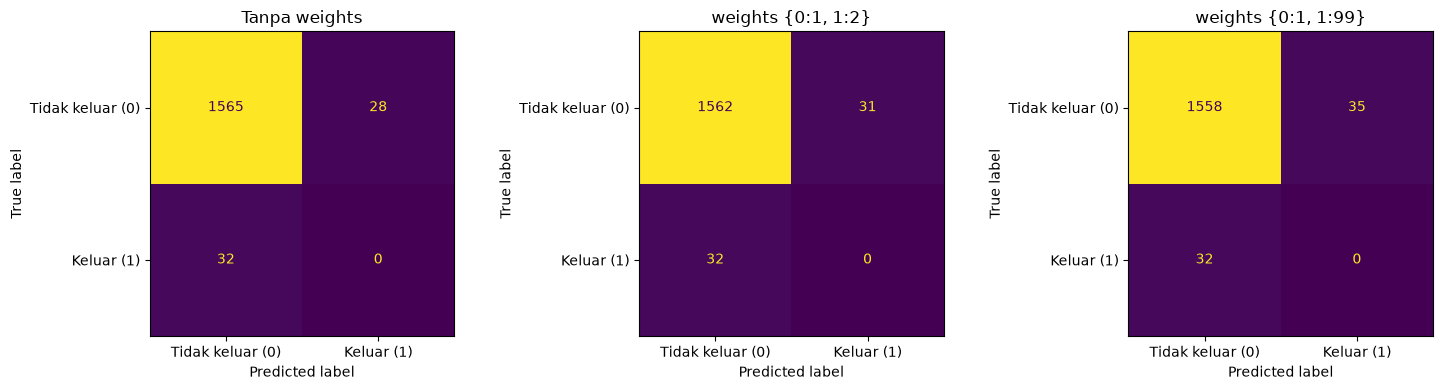

In [19]:
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, random_state=42, test_size=0.2)
configs = {'Tanpa weights': None, 'weights {0:1, 1:2}': {0: 1, 1: 2}, 'weights {0:1, 1:99}': {0: 1, 1: 99}}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, w) in zip(axes, configs.items()):
    pred = DecisionTreeClassifier(random_state=42, class_weight=w).fit(X_train, y_train).predict(X_test)
    print(f'{name}: F1 macro = {f1_score(y_test, pred, average="macro"):.4f}')
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Tidak keluar (0)', 'Keluar (1)']).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout(); plt.show()

b) Berdasarkan jawaban pada soal (4a), Apakah terdapat perbedaan pada confusion matrix dan score f1 macro masing-masing weights? Jelaskan.

**Jawaban:** Ada perbedaan, tetapi **sangat kecil** dan tidak membuat model lebih baik.

| class_weight | F1 macro | TN | FP | FN | TP |
|---|---|---|---|---|---|
| tanpa weights | 0,4906 | 1.565 | 28 | 32 | 0 |
| {0:1, 1:2} | 0,4901 | 1.562 | 31 | 32 | 0 |
| {0:1, 1:99} | 0,4895 | 1.558 | 35 | 32 | 0 |

Makin besar bobot kelas 1, makin banyak *false positive* (28 → 31 → 35) dan F1 macro turun tipis, tetapi **TP tetap 0**: tidak ada satu pun dari 32 nasabah yang keluar berhasil terdeteksi.

Mengapa bobot nyaris tidak berpengaruh: `DecisionTreeClassifier` tanpa batas kedalaman tumbuh sampai semua data latih terklasifikasi sempurna (akurasi latih = 1,0; kedalaman 33–34, 242–281 daun) dengan bobot apa pun. Bobot hanya mengubah penghitungan impurity saat memilih pemisahan, bukan kemampuan pohon menghafal. Bobot baru terasa pada model yang tidak bisa memuat semua data (misalnya pohon dengan `max_depth` kecil atau model teregularisasi). Selain itu, kedua fitur memang hampir tidak informatif, jadi tidak ada pola yang bisa "dibantu" oleh bobot.

Referensi: dokumentasi scikit-learn `DecisionTreeClassifier` (parameter `class_weight`); Elkan, C. (2001). *The foundations of cost-sensitive learning*. IJCAI-01, 973–978; He & Garcia (2009), bagian *cost-sensitive methods*.

## 5. Neural Network dan Pipeline

a) Buatlah sebuah model MLPClassifier dengan kriteria sebagai berikut:
- Memiliki 3 hidden layer dengan masing - masing layer terdiri dari 50, 40, dan 20 berturut - turut
- Menggunakan random_state=42
- Abaikan hyperparameter lain

In [20]:
mlp_a = MLPClassifier(hidden_layer_sizes=(50, 40, 20), random_state=42)

b) Buatlah sebuah model MLPClassifier dengan kriteria sebagai berikut:
- Memiliki 2 hidden layer dengan masing - masing layer terdiri dari 100 dan 80 berturut - turut
- Menggunakan random_state=42
- Abaikan hyperparameter lain

In [21]:
mlp_b = MLPClassifier(hidden_layer_sizes=(100, 80), random_state=42)

c) Lakukan cross validation menggunakan **Stratified K-fold** dengan k=5 dan random_state=42 terhadap kedua model MLP pada soal (5a) dan (5b) memakai X dan y yang didefinisikan pada soal (1a). Metrik evaluasi yang digunakan adalah f1 macro dan f1 micro. Tampilkan hasil rata-rata dari metriknya

In [22]:
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
models_5 = {'MLP (50,40,20)': mlp_a, 'MLP (100,80)': mlp_b}

def cv_summary(estimators):
    rows = {}
    for name, est in estimators.items():
        cv_res = cross_validate(est, X, y, cv=skf5, scoring=['f1_macro', 'f1_micro'])
        rows[name] = {'f1_macro': cv_res['test_f1_macro'].mean(), 'f1_micro': cv_res['test_f1_micro'].mean()}
    return pd.DataFrame(rows).T

res_5c = cv_summary(models_5)
res_5c

,f1_macro,f1_micro
"MLP (50,40,20)",0.496664,0.966628
"MLP (100,80)",0.475115,0.905421


d) Apakah terdapat perbedaan skor metrik makro evaluasi model pada soal (5c)? Jelaskan keterkaitan perbedaan skor dengan perbedaan hyperparameter kedua model!

**Jawaban:** Ya, ada perbedaan.

| Model | F1 macro | F1 micro |
|---|---|---|
| MLP (50, 40, 20) | 0,4967 | 0,9666 |
| MLP (100, 80) | 0,4751 | 0,9054 |

MLP (50,40,20) lebih tinggi. Pada data ini F1 micro sama dengan akurasi, dan prediksi "selalu 0" sudah menghasilkan 0,9804, jadi kedua model sebenarnya tidak melampaui tebakan mayoritas. Skor makro ≈ 0,5 pada keduanya berarti setara tebakan acak untuk kelas minoritas.

Kaitan dengan hyperparameter: MLP (100,80) punya 8.461 parameter, sedangkan (50,40,20) hanya 3.031, jadi kapasitasnya lebih besar. Pada data yang praktis tanpa sinyal, kapasitas ekstra itu hanya dipakai untuk mengikuti *noise*: model (100,80) memprediksi kelas 1 pada 7,8% data (622 *false positive*), versus 1,5% (116 *false positive*) pada model yang lebih kecil. Faktor lain yang mungkin memperburuk: fitur tidak diskalakan (nilai Balance/Salary sampai ratusan ribu) sehingga aktivasi dan gradien besar, dan lapisan yang lebih lebar memperbesar efek itu; pelatihan juga berhenti di `max_iter=200` sebelum konvergen (peringatan disembunyikan). Dua faktor terakhir ini hipotesis yang belum diuji terpisah.

Referensi: dokumentasi scikit-learn `MLPClassifier`; Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press, bab 5.2 (kapasitas, *overfitting*) dan 8.2 (optimasi).

e) Dengan menggunakan Pipeline, lakukan cross validation menggunakan **Stratified K-fold** dengan k=5 dan random_state=42 pada sebuah pipeline yang berisi steps yaitu oversampling menggunakan SMOTE dengan random_state=42 dan menggunakan model MLP yang memiliki performa lebih bagus dari soal (5a) dan (5b). Gunakan X dan y yang didefinisikan pada soal (1a) untuk melakukan cross validation. Metrik evaluasi yang digunakan adalah f1 macro dan f1 micro. Tampilkan hasil rata-rata dari metriknya

In [23]:
best_name = res_5c['f1_macro'].idxmax()
print('MLP terbaik dari 5c:', best_name)
pipe_smote = Pipeline([('smote', SMOTE(random_state=42)), ('mlp', clone(models_5[best_name]))])
res_5e = cv_summary({f'SMOTE + {best_name}': pipe_smote})
res_5e

MLP terbaik dari 5c: MLP (50,40,20)


,f1_macro,f1_micro
"SMOTE + MLP (50,40,20)",0.341929,0.513681


f) Dengan menggunakan Pipeline, lakukan cross validation menggunakan **Stratified K-fold** dengan k=5 dan random_state=42 pada sebuah pipeline yang berisi steps yaitu undersampling menggunakan RandomUnderSampler dengan random_state=42 dan menggunakan model MLP yang memiliki performa lebih bagus dari soal (5a) dan (5b). Gunakan X dan y yang didefinisikan pada soal (1a) untuk melakukan cross validation. Metrik evaluasi yang digunakan adalah f1 macro dan f1 micro. Tampilkan hasil rata-rata dari metriknya

In [24]:
pipe_rus = Pipeline([('rus', RandomUnderSampler(random_state=42)), ('mlp', clone(models_5[best_name]))])
res_5f = cv_summary({f'RandomUnderSampler + {best_name}': pipe_rus})
display(res_5f)
pd.concat([res_5c, res_5e, res_5f])

,f1_macro,f1_micro
"RandomUnderSampler + MLP (50,40,20)",0.29724,0.436762


,f1_macro,f1_micro
"MLP (50,40,20)",0.496664,0.966628
"MLP (100,80)",0.475115,0.905421
"SMOTE + MLP (50,40,20)",0.341929,0.513681
"RandomUnderSampler + MLP (50,40,20)",0.297240,0.436762


**Ringkasan 5e dan 5f** (MLP terbaik dari 5c = (50,40,20); `Pipeline` dari imbalanced-learn sehingga resampling hanya dijalankan pada data latih tiap fold):

| Model | F1 macro | F1 micro |
|---|---|---|
| MLP (50,40,20) tanpa resampling | 0,4967 | 0,9666 |
| SMOTE + MLP | 0,3419 | 0,5137 |
| RandomUnderSampler + MLP | 0,2972 | 0,4368 |

**Jawaban:** Kedua pipeline justru *lebih buruk* daripada tanpa resampling. Setelah data diseimbangkan, model belajar bahwa peluang kelas 1 sekitar 50%, lalu dipakai pada data validasi yang 98% kelas 0. Akibatnya sangat banyak *false positive*, akurasi (= F1 micro) jatuh ke ±0,5 dan F1 kelas 0 turun, sehingga F1 macro juga turun. Karena fitur tidak punya sinyal, resampling tidak bisa memperbaiki apa pun, hanya menggeser prior model. SMOTE (0,34) sedikit lebih baik daripada RandomUnderSampler (0,30) karena RandomUnderSampler membuang 7.803 dari 7.962 sampel mayoritas dan melatih model hanya dengan 318 sampel, sedangkan SMOTE mempertahankan seluruh data asli.

Metrik F1 micro menyesatkan untuk data tidak seimbang (nilai 0,97 pada model tanpa resampling hanya mencerminkan dominasi kelas 0), jadi F1 macro atau metrik per kelas lebih layak dipakai.

## 6. Soal Teoritis Neural Network

a) Apabila dalam binary classification dibutuhkan 1 neuron dalam output layer, berapa neuron yang dibutuhkan dalam output layer untuk multiclass classification? Berikan contoh dan sertakan sumber referensi yang kalian gunakan.

**Jawaban:** Pada binary classification cukup **1 neuron** output (aktivasi sigmoid: keluarannya P(kelas 1)). Pada multiclass classification dengan **K kelas**, dibutuhkan **K neuron** output, satu per kelas, dengan aktivasi **softmax** sehingga keluaran berupa K probabilitas yang jumlahnya 1. Kelas prediksi adalah neuron dengan nilai terbesar.

Contoh: klasifikasi bunga iris (setosa, versicolor, virginica) → 3 neuron output; pengenalan digit tulisan tangan MNIST (0–9) → 10 neuron output. (Binary juga bisa memakai 2 neuron + softmax; hasilnya setara dengan 1 neuron sigmoid. Untuk *multi-label*, K neuron dengan sigmoid masing-masing.) Di scikit-learn, `MLPClassifier` otomatis memakai logistic untuk binary dan softmax untuk multiclass (atribut `out_activation_`).

Referensi: Goodfellow, I., Bengio, Y., & Courville, A. (2016). *Deep Learning*. MIT Press, §6.2.2.3 (*Softmax Units for Multinoulli Output Distributions*); dokumentasi scikit-learn `MLPClassifier`, https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html.

b) Diketahui terdapat hyperparameter berikut pada MLPClassifier:
- hidden_layer_sizes
- learning_rate_init

Untuk masing-masing hyperparameter tersebut, jelaskan apa yang akan terjadi jika kita menetapkan value yang berbeda (misalnya menjelaskan perbedaan hidden_layer_size=(50,50) vs (100,50), dsb.). Asumsikan hyperparameter learning_rate yang dipakai adalah constant.

Sertakan sumber referensi anda.

**Jawaban:**

**`hidden_layer_sizes`** menentukan jumlah lapisan tersembunyi dan neuron per lapisan, sehingga menentukan kapasitas model.
- Lebih banyak neuron/lapisan → lebih banyak parameter dan fungsi yang lebih rumit bisa dipelajari, tetapi risiko *overfitting* lebih besar dan pelatihan lebih lambat. Terlalu sedikit → *underfitting*.
- Contoh dengan 2 fitur input: `(50, 50)` punya 2.751 parameter, `(100, 50)` punya 5.401, yaitu lapisan pertama dilebarkan sehingga model dapat menangkap lebih banyak kombinasi fitur awal. `(50, 50, 50)` lebih dalam daripada `(50, 50)`: bisa membentuk representasi bertingkat, tetapi lebih sulit dioptimasi.

**`learning_rate_init`** adalah ukuran langkah pembaruan bobot pada tiap iterasi (bila learning rate konstan, nilainya tidak berubah selama pelatihan).
- Terlalu besar (misal 1,0): loss berosilasi atau divergen karena langkah "melompati" titik minimum.
- Terlalu kecil (misal 0,00001): pelatihan sangat lambat dan bisa berhenti di `max_iter` sebelum konvergen, atau tersangkut di dataran (*plateau*).
- Nilai default 0,001 biasanya kompromi yang wajar; keduanya perlu disetel bersama karena model yang lebih besar sering butuh learning rate yang lebih kecil.

Referensi: dokumentasi scikit-learn `MLPClassifier` (parameter `hidden_layer_sizes`, `learning_rate_init`); Goodfellow dkk. (2016). *Deep Learning*, bab 8 (optimasi, termasuk pemilihan learning rate); Bengio, Y. (2012). *Practical recommendations for gradient-based training of deep architectures*. Dalam *Neural Networks: Tricks of the Trade* (edisi ke-2), Springer; juga tersedia sebagai arXiv:1206.5533.